In [47]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn import metrics
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import os
os.chdir("D:/gus6e/Documents")


In [48]:
col_names = ["pregnant", "glucose", "bp", "skin", "insulin", "bmi", "pedigre", "age", "label"]
pima = pd.read_csv("diabetes.csv", header = None, names = col_names)
df = pima.iloc[1:,:]
df

,pregnant,glucose,bp,skin,insulin,bmi,pedigre,age,label
1,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0
5,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
764,10,101,76,48,180,32.9,0.171,63,0
765,2,122,70,27,0,36.8,0.34,27,0
766,5,121,72,23,112,26.2,0.245,30,0
767,1,126,60,0,0,30.1,0.349,47,1


In [49]:
# Selección de las características
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigre"]
x = df[feature_cols]
y = df.label

In [50]:
# Creación de las bases de entrenamiento de prueba
x_train, x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2, random_state = 1)

In [51]:
# sag: Stochastic Average Gradient
# newton-cg: Newton
# liblinear: Library for large linear Classification (Algoritmo Coordinate Descent)
# saga: Variante del m+etodo sag
# lbfgs: Limited-memory Broyden-Fletcher-Goldfarb-Shanno Algorithm

# Regresión logística con Solucionador (Solver): sag

In [52]:
model = LogisticRegression(solver="sag")
clf = model.fit(x_train,y_train)

In [53]:
# Predicción de etiquetas de clase sobre datos de prueba
y_pred = model.predict(x_test)

# Impresión de coeficientes de la regresión de puntajes
print("Intercepto (Beta 0)",clf.intercept_)
print("Pesos de cada variable (Beta1, Beta2, ... , Beta7)",clf.coef_)

Intercepto (Beta 0) [-0.01188832]
Pesos de cada variable (Beta1, Beta2, ... , Beta7) [[ 0.05225481  0.00116535 -0.00937377 -0.00234782  0.0140794  -0.0308459
   0.00106175]]


In [54]:
# Evaluación de la precisión del modelo
score = model.score(x_test, y_test)
print("Score de precisión: ", score)

Score de precisión:  0.6428571428571429


In [55]:
# Reporte de clasificación
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.67      0.89      0.76        99
           1       0.50      0.20      0.29        55

    accuracy                           0.64       154
   macro avg       0.58      0.54      0.52       154
weighted avg       0.61      0.64      0.59       154



# Regresión logística con Solucionador (Solver): newton-cg

In [56]:
model = LogisticRegression(solver = "newton-cg")
clf = model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Intercepto (Beta 0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("____________________________________________________________")
score = model.score(x_test,y_test)
print("Precisión global:", score)
print("____________________________________________________________")
print(classification_report(y_test,y_pred))

Intercepto (Beta 0): [-8.09012854]
Pesos (Betas): [[ 0.12708994 -0.00095867  0.08544502  0.01165685  0.03653159 -0.01510542
   0.63052976]]
____________________________________________________________
Precisión global: 0.7727272727272727
____________________________________________________________
              precision    recall  f1-score   support

           0       0.78      0.90      0.84        99
           1       0.75      0.55      0.63        55

    accuracy                           0.77       154
   macro avg       0.77      0.72      0.73       154
weighted avg       0.77      0.77      0.76       154



# Regresión logística con Solucionador (Solver): liblinear

In [57]:
model = LogisticRegression(solver = "liblinear")
clf = model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Intercepto (Beta 0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("____________________________________________________________")
score = model.score(x_test,y_test)
print("Precisión global:", score)
print("____________________________________________________________")
print(classification_report(y_test,y_pred))

Intercepto (Beta 0): [-5.3789679]
Pesos (Betas): [[ 1.18839257e-01 -3.16887240e-04  5.28139709e-02  3.80223853e-03
   2.87897610e-02 -1.91009580e-02  4.74700127e-01]]
____________________________________________________________
Precisión global: 0.7662337662337663
____________________________________________________________
              precision    recall  f1-score   support

           0       0.77      0.90      0.83        99
           1       0.74      0.53      0.62        55

    accuracy                           0.77       154
   macro avg       0.76      0.71      0.72       154
weighted avg       0.76      0.77      0.76       154



# Regresión logística con Solucionador (Solver): saga

In [58]:
model = LogisticRegression(solver = "saga")
clf = model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Intercepto (Beta 0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("____________________________________________________________")
score = model.score(x_test,y_test)
print("Precisión global:", score)
print("____________________________________________________________")
print(classification_report(y_test,y_pred))

Intercepto (Beta 0): [-0.00610513]
Pesos (Betas): [[ 0.03014979  0.00115497 -0.00950416  0.00094429  0.01389263 -0.03082723
   0.00047058]]
____________________________________________________________
Precisión global: 0.6493506493506493
____________________________________________________________
              precision    recall  f1-score   support

           0       0.67      0.89      0.77        99
           1       0.52      0.22      0.31        55

    accuracy                           0.65       154
   macro avg       0.60      0.55      0.54       154
weighted avg       0.62      0.65      0.60       154



# Regresión logística con Solucionador (Solver): lbfgs

In [59]:
model = LogisticRegression(solver = "lbfgs")
clf = model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Intercepto (Beta 0):", clf.intercept_)
print("Pesos (Betas):", clf.coef_)
print("____________________________________________________________")
score = model.score(x_test,y_test)
print("Precisión global:", score)
print("____________________________________________________________")
print(classification_report(y_test,y_pred))

Intercepto (Beta 0): [-8.10385838]
Pesos (Betas): [[ 0.12715713 -0.00096267  0.08559411  0.01168201  0.0365709  -0.01508643
   0.63352688]]
____________________________________________________________
Precisión global: 0.7727272727272727
____________________________________________________________
              precision    recall  f1-score   support

           0       0.78      0.90      0.84        99
           1       0.75      0.55      0.63        55

    accuracy                           0.77       154
   macro avg       0.77      0.72      0.73       154
weighted avg       0.77      0.77      0.76       154



In [60]:
# Predicción de probabilidades para casos particulares
y_pred_probs = clf.predict_proba(x_test)[:,1]
y_pred_probs[0:5]

array([0.43650672, 0.31967424, 0.15787836, 0.0434014 , 0.19968366])

In [61]:
y_test[0:5]

286    0
102    0
582    0
353    0
727    0
Name: label, dtype: object

In [62]:
y_test = y_test.to_numpy()
y_test[0:5]

array(['0', '0', '0', '0', '0'], dtype=object)

In [67]:
y_test = [int(numeric_string) for numeric_string in y_test]
y_test[0:5]

[0, 0, 0, 0, 0]

In [68]:
import numpy as np
y_pred_probs = np.round(y_pred_probs,0)
y_pred_probs[0:5]

array([0., 0., 0., 0., 0.])

In [69]:
# Graficación de la curva ROC y cálculo del área bajo la curva
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
# fpr = false positive rate
# tpr = true positive rate
# tresholds = límites para valores de p
fpr,tpr, tresholds = roc_curve(y_test,y_pred_probs)
auc = roc_auc_score(y_test,y_pred_probs)

Text(0.5, 1.0, 'Curva ROC para Regresión Logística')

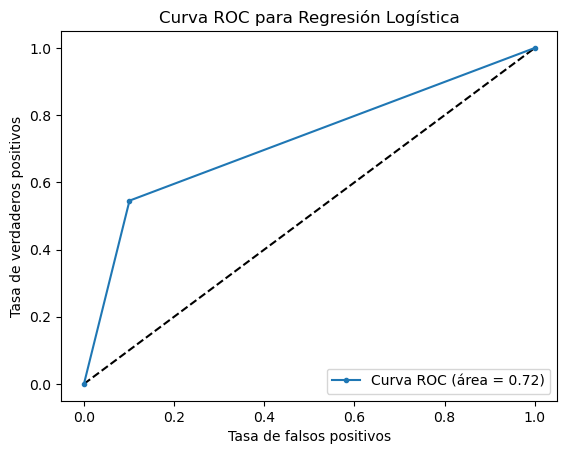

In [70]:
plt.plot([0,1],[0,1], "k--")
plt.plot(fpr,tpr,marker= ".", label = "Curva ROC (área = %0.2f)" % auc)
plt.xlabel("Tasa de falsos positivos") #False positive rate
plt.ylabel("Tasa de verdaderos positivos") #True positive rate
plt.legend(loc = "lower right")
plt.title("Curva ROC para Regresión Logística")